In [ ]:
!pip install albumentations

In [ ]:
import os
import random
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import shutil

import albumentations as A
from albumentations.pytorch import ToTensorV2
import torchvision.models as models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from tqdm.auto import tqdm
import json

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

In [ ]:
!pip install optuna -q

import optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.4 MB/s eta 0:00:00


In [ ]:
def set_seed(seed=42):
    """Set the seed for reproducability"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
SEED = 42

**Mount the drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Exploring the dataset**

In [ ]:
train_df = pd.read_csv("/content/drive/MyDrive/aptos2019-blindness-detection/train.csv")
folder = "/content/drive/MyDrive/aptos2019-blindness-detection/train_images"

print(train_df.head(15))
print(len(os.listdir(folder)))

         id_code  diagnosis
0   000c1434d8d7          2
1   001639a390f0          4
2   0024cdab0c1e          1
3   002c21358ce6          0
4   005b95c28852          0
5   0083ee8054ee          4
6   0097f532ac9f          0
7   00a8624548a9          2
8   00b74780d31d          2
9   00cb6555d108          1
10  00cc2b75cddd          0
11  00e4ddff966a          2
12  00f6c1be5a33          0
13  0104b032c141          3
14  0124dffecf29          1
3662


**We copy the image folder to local disk once; every epoch after that reads from local SSD instead of over the network.**

In [ ]:
DRIVE_IMAGE_DIR = "/content/drive/MyDrive/aptos2019-blindness-detection/train_images"
LOCAL_IMAGE_DIR = "/content/train_images"

expected = len(os.listdir(DRIVE_IMAGE_DIR))
if not os.path.exists(LOCAL_IMAGE_DIR) or len(os.listdir(LOCAL_IMAGE_DIR)) != expected:
    shutil.rmtree(LOCAL_IMAGE_DIR, ignore_errors=True)
    shutil.copytree(DRIVE_IMAGE_DIR, LOCAL_IMAGE_DIR)
    print(f"Done. {len(os.listdir(LOCAL_IMAGE_DIR))} images copied to {LOCAL_IMAGE_DIR}")
else:
    print(f"Local copy already exists and is complete ({len(os.listdir(LOCAL_IMAGE_DIR))} images) -- skipping copy.")

Done. 3662 images copied to /content/train_images


**Displaying 3 images from each class of DR**

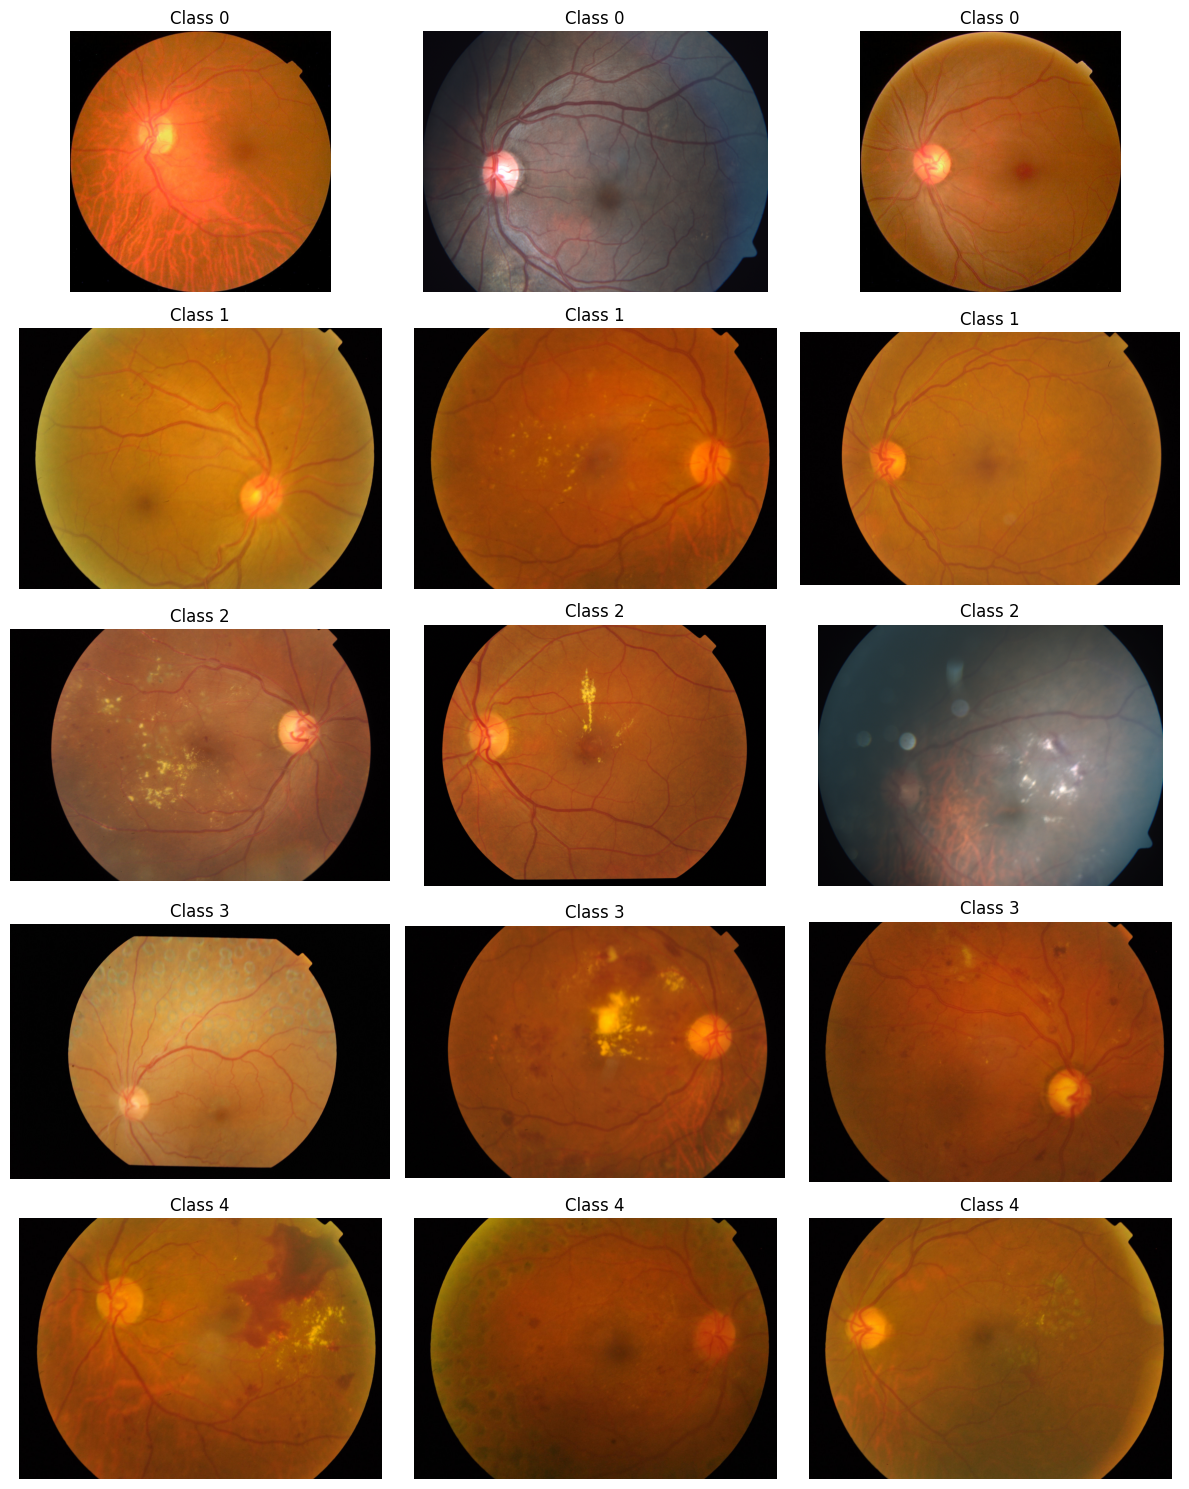

In [ ]:
IMAGE_DIR = LOCAL_IMAGE_DIR

classes = sorted(train_df['diagnosis'].unique())

fig, axes = plt.subplots(len(classes), 3, figsize=(12, 15))

for row, cls in enumerate(classes):

    # get 3 samples from this class
    samples = train_df[train_df['diagnosis'] == cls].sample(3)

    for col, (_, sample) in enumerate(samples.iterrows()):

        img_path = os.path.join(IMAGE_DIR, sample['id_code'] + ".png")
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[row, col].imshow(img)
        axes[row, col].set_title(f"Class {cls}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

**The dataset is split 70/10/20 into train, test and validation set using stratified sampling to preserve the original class distribution.**

In [ ]:
train_df["image_path"] = train_df["id_code"].apply(lambda x: os.path.join(IMAGE_DIR, x + ".png"))

full_df = pd.read_csv("/content/drive/MyDrive/aptos2019-blindness-detection/train.csv")
full_df["image_path"] = full_df["id_code"].apply(lambda x: os.path.join(IMAGE_DIR, x + ".png"))

train_val_df, test_df = train_test_split(
    full_df, test_size=0.20, stratify=full_df["diagnosis"], random_state=42
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.125, stratify=train_val_df["diagnosis"], random_state=42
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 2562 | Val: 367 | Test: 733


**Printing training, test and validation set lengths**

In [ ]:
print(train_df["diagnosis"].value_counts())
print(val_df["diagnosis"].value_counts())
print(test_df["diagnosis"].value_counts())

diagnosis
0    1263
2     699
1     259
4     206
3     135
Name: count, dtype: int64
diagnosis
0    181
2    100
1     37
4     30
3     19
Name: count, dtype: int64
diagnosis
0    361
2    200
1     74
4     59
3     39
Name: count, dtype: int64


**Oversampling the training set only**

In [ ]:
print("Class distribution BEFORE oversampling:")
print(train_df["diagnosis"].value_counts().sort_index())

from sklearn.utils import resample

class_counts = train_df["diagnosis"].value_counts()
max_class_count = class_counts.max()

oversampled_dfs = []
for label in class_counts.index:
    class_subset = train_df[train_df["diagnosis"] == label]
    n_needed = max_class_count - len(class_subset)
    if n_needed <= 0:
        oversampled_subset = class_subset
    else:
        extra = class_subset.sample(n=n_needed, replace=True, random_state=42)
        oversampled_subset = pd.concat([class_subset, extra])
    oversampled_dfs.append(oversampled_subset)

train_df = pd.concat(oversampled_dfs).sample(frac=1, random_state=42).reset_index(drop=True)

print("\nClass distribution AFTER oversampling:")
print(train_df["diagnosis"].value_counts().sort_index())

print(f"\ntrain_df size: {len(train_df)} (was {sum(class_counts)} before oversampling)")
print(f"val_df size: {len(val_df)} (unchanged)")

Class distribution BEFORE oversampling:
diagnosis
0    1263
1     259
2     699
3     135
4     206
Name: count, dtype: int64

Class distribution AFTER oversampling:
diagnosis
0    1263
1    1263
2    1263
3    1263
4    1263
Name: count, dtype: int64

train_df size: 6315 (was 2562 before oversampling)
val_df size: 367 (unchanged)


**Graphs of before and after of oversampling**

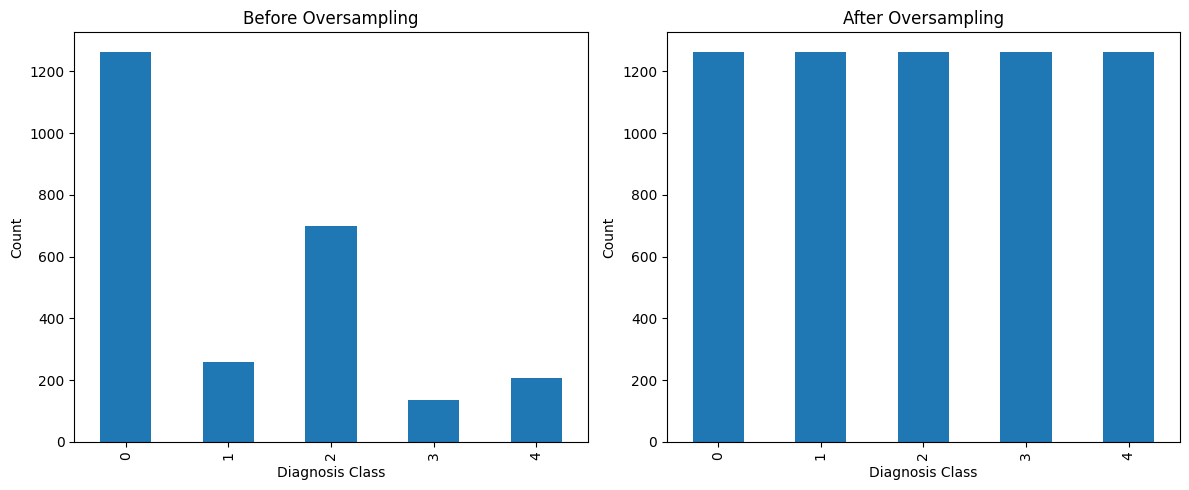

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
class_counts.sort_index().plot(kind='bar', ax=axes[0], title='Before Oversampling')
train_df["diagnosis"].value_counts().sort_index().plot(kind='bar', ax=axes[1], title='After Oversampling')
for ax in axes:
    ax.set_xlabel('Diagnosis Class')
    ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

**APTOS 2019 Image preprocessing**

In [ ]:
def crop_image_from_gray(img,tol=7):
    if img.ndim ==2:
        mask = img>tol
        return img[np.ix_(mask.any(1),mask.any(0))]
    elif img.ndim==3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        mask = gray_img>tol

        check_shape = img[:,:,0][np.ix_(mask.any(1),mask.any(0))].shape[0]
        if (check_shape == 0): # image is too dark so that we crop out everything,
            return img # return original image
        else:
            img1=img[:,:,0][np.ix_(mask.any(1),mask.any(0))]
            img2=img[:,:,1][np.ix_(mask.any(1),mask.any(0))]
            img3=img[:,:,2][np.ix_(mask.any(1),mask.any(0))]
            img = np.stack([img1,img2,img3],axis=-1)
        return img


def circle_crop(img, sigmaX):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # convert from BGR to RGB first
    img = crop_image_from_gray(img)              # now we call the RGB2GRAY function

    height, width, depth = img.shape

    x = int(width/2)
    y = int(height/2)
    r = np.amin((x,y))

    circle_img = np.zeros((height, width), np.uint8)
    cv2.circle(circle_img, (x,y), int(r), 1, thickness=-1)
    img = cv2.bitwise_and(img, img, mask=circle_img)
    img = crop_image_from_gray(img)
    img=cv2.addWeighted(img,4, cv2.GaussianBlur( img , (0,0) , sigmaX) ,-4 ,128)
    return img

**Running preprocessing techniques for images**

In [ ]:
CROPPED_IMAGE_DIR = "/content/drive/MyDrive/aptos2019-blindness-detection/train_images_cropped"
os.makedirs(CROPPED_IMAGE_DIR, exist_ok=True)

all_paths = pd.concat([train_df, val_df, test_df])["image_path"].unique()


for path in tqdm(all_paths, desc="Precomputing crops"):
    fname = os.path.basename(path)
    out_path = os.path.join(CROPPED_IMAGE_DIR, fname)
    if os.path.exists(out_path):
        continue
    img = cv2.imread(path)
    img = circle_crop(img, sigmaX=30)
    img = cv2.resize(img, (224, 224))
    Image.fromarray(img).save(out_path)

Precomputing crops:   0%|          | 0/3662 [00:00<?, ?it/s]

**APTOS dataset class**

In [ ]:
class APTOSDataset(Dataset):

    def __init__(self, dataframe, transform=None, cropped_dir=CROPPED_IMAGE_DIR):
        self.df = dataframe
        self.transform = transform
        self.cropped_dir = cropped_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image_path"]
        label = self.df.iloc[idx]["diagnosis"]

        fname = os.path.basename(img_path)
        image = np.array(Image.open(os.path.join(self.cropped_dir, fname)).convert("RGB"))

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, label

**Defining the augmentation transforms.**

**Training transforms**

In [ ]:
train_transforms = A.Compose([

    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),

    A.Rotate(limit=90, p=0.5),

    A.Sharpen(alpha=(0.2, 0.5), lightness=(0.5, 1.0), p=0.5),
    A.Emboss(alpha=(0.2, 0.5), strength=(0.2, 0.7), p=0.5), # more aug

    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),#more aug
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

**Validation and test transforms**

In [ ]:
val_transforms = A.Compose([
    A.Resize(224,224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

**Creating APTOS Datasets for train, validation and test set**

In [ ]:
train_dataset = APTOSDataset(train_df, transform=train_transforms)
val_dataset = APTOSDataset(val_df, transform=val_transforms)
test_dataset = APTOSDataset(test_df, transform=val_transforms)

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

6315
367
733


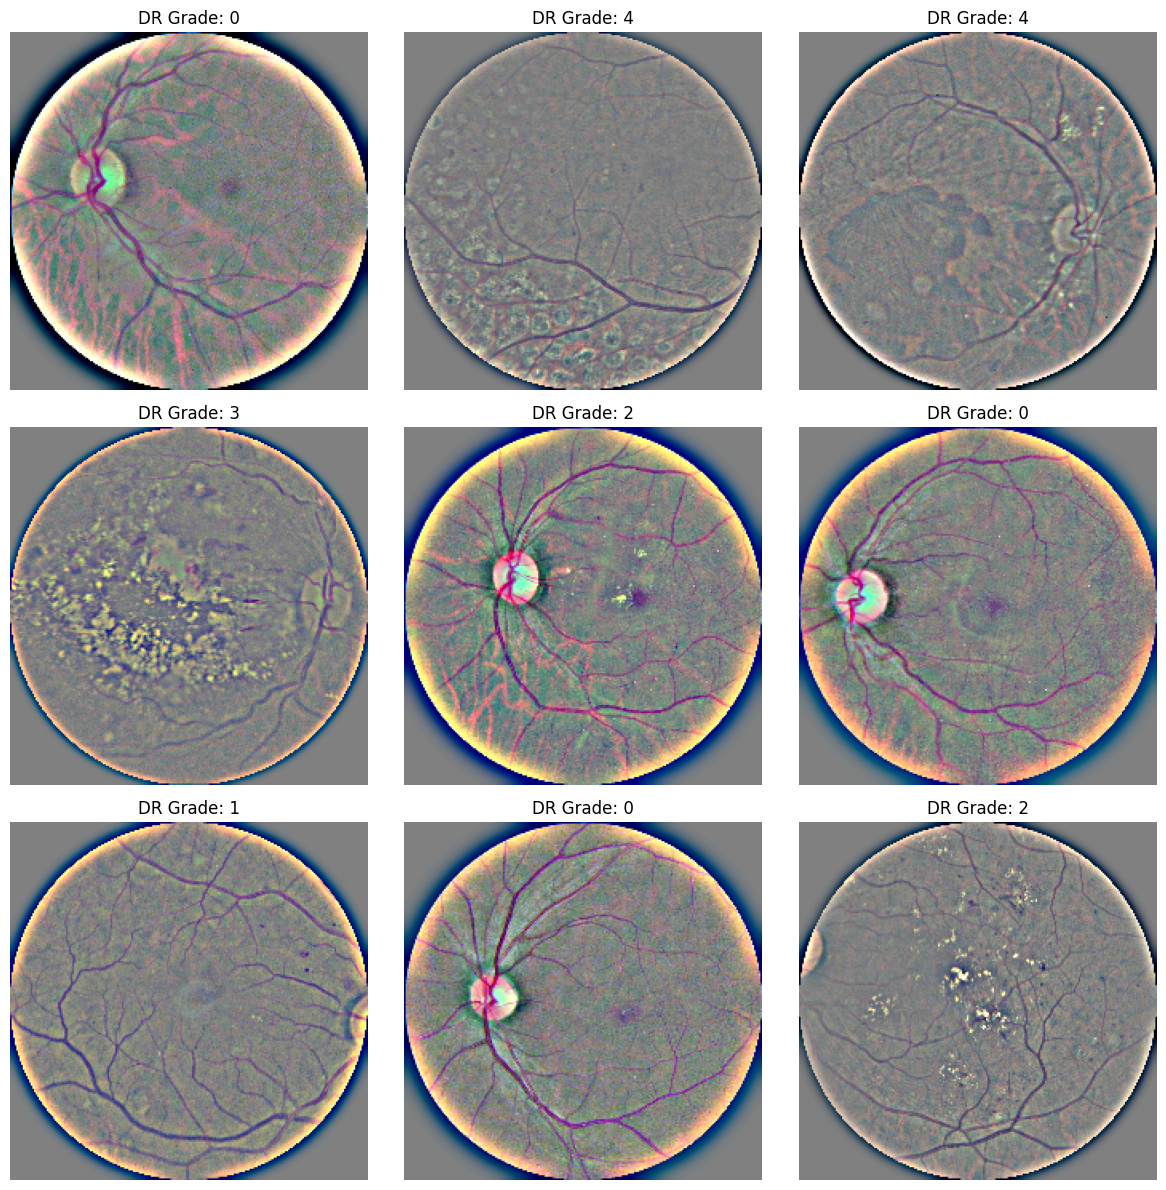

In [ ]:
preprocessed_dataset = APTOSDataset(train_df,transform=None)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, ax in enumerate(axes.flat):

    image, label = preprocessed_dataset[i]

    ax.imshow(image)
    ax.set_title(f"DR Grade: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**A visual display of some of our augmentations being applied to the images**

In [ ]:
duplicated_paths = train_df["image_path"][train_df["image_path"].duplicated(keep=False)]
sample_path = duplicated_paths.iloc[0]
sample_indices = train_df.index[train_df["image_path"] == sample_path].tolist()

print(f"This image appears {len(sample_indices)} times in train_df due to oversampling")

outputs = [train_dataset[idx][0] for idx in sample_indices]
diffs = [not torch.equal(outputs[0], o) for o in outputs[1:]]
print(f"Differed from the first copy in {sum(diffs)}/{len(diffs)} of the other duplicate rows")

This image appears 11 times in train_df due to oversampling
Differed from the first copy in 10/10 of the other duplicate rows


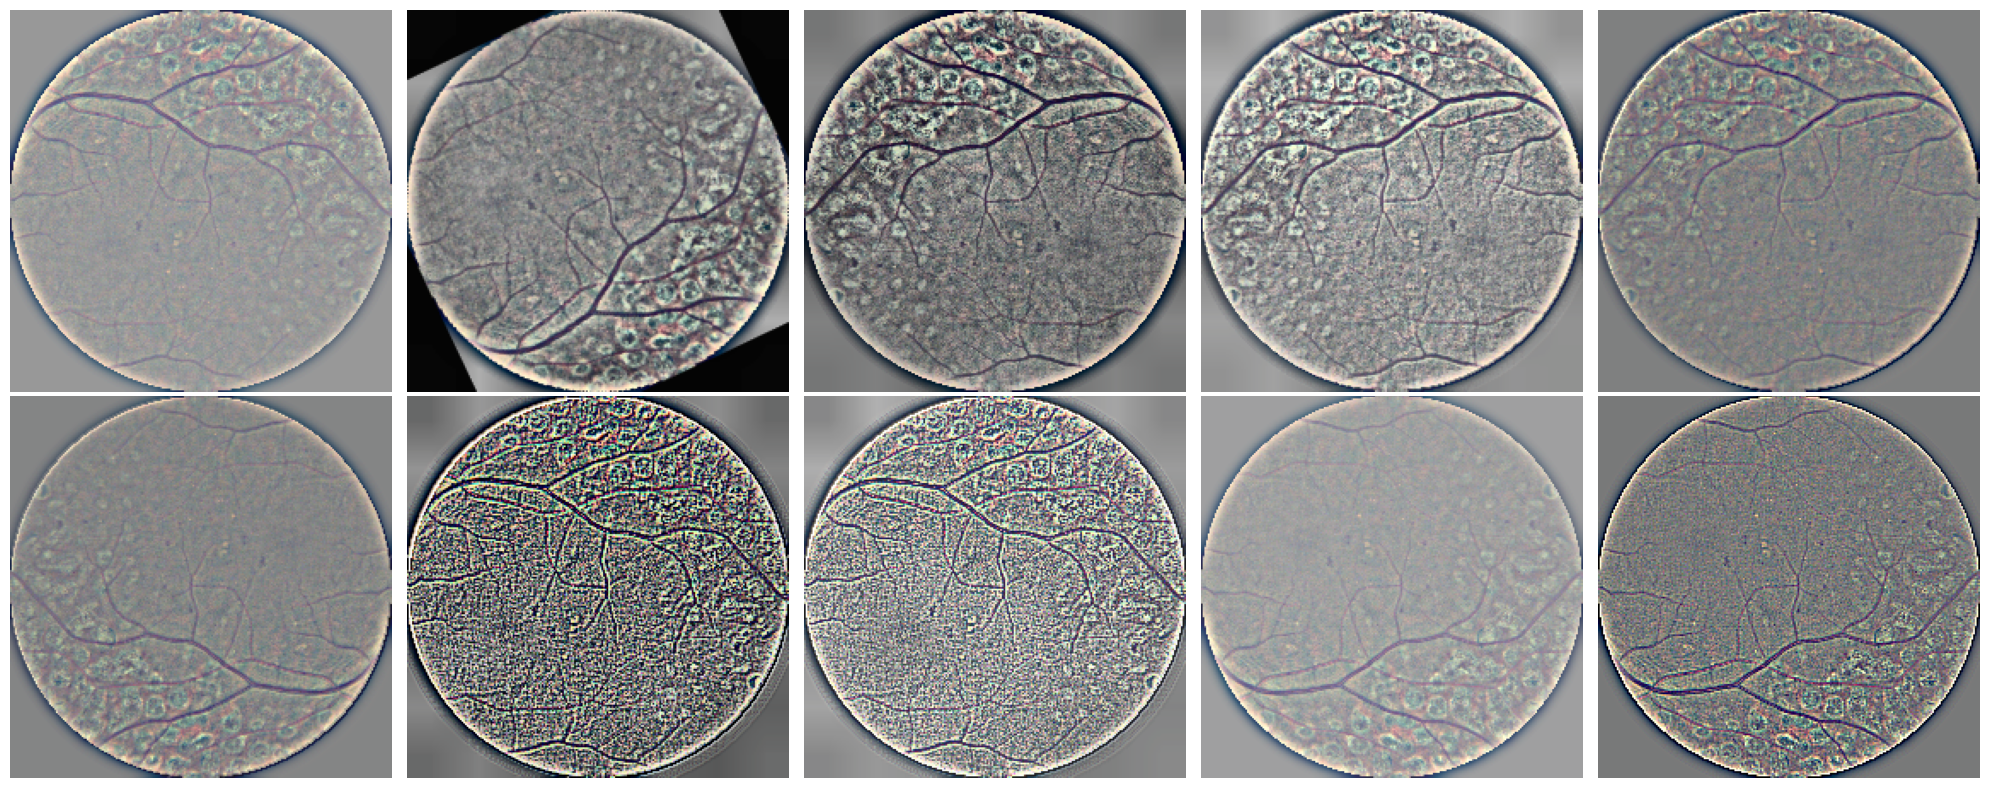

In [ ]:
n = len(sample_indices)
ncols = min(n, 5)
nrows = (n // ncols)  # ceiling division

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
axes = np.atleast_1d(axes).flatten()

for ax, idx in zip(axes, sample_indices):
    img_tensor, _ = train_dataset[idx]
    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_np = np.clip(img_np, 0, 1)
    ax.imshow(img_np)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Creating train, validation and test loaders**

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False
)

**Grabbing the images and labels of the training images from our train loader**

In [ ]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


**Setting the device**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


In [ ]:
def compute_qwk(y_true, y_pred):
    """Compute QWK"""
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")

# **ResNet50**

**Loading pretrained ResNet50 Model**

In [ ]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(0.5), # Randomly turns off 50% of the neural connections during training. Prevents overfitting.
    nn.Linear(num_features, 5) # Takes 2048 features and maps them to 5 classes to predict the 5 classes of DR.
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]


**Skipping if ResNet50 weights already exist**

In [ ]:
drive_model_dir = "/content/drive/MyDrive/aptos2019-blindness-detection/models"
os.makedirs(drive_model_dir, exist_ok=True)
checkpoint_path = os.path.join(drive_model_dir, "resnet50_best_model.pth")

resnet50_skip_training = os.path.exists(checkpoint_path)

if resnet50_skip_training:
    print(f"Found existing weights at {checkpoint_path} -- loading them and skipping training.")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model = model.to(device)
else:
    print("No saved weights found on Drive -- will train from scratch.")

No saved weights found on Drive -- will train from scratch.


**We implement transfer learning using a pretrained ResNet50 model, with the final layer replaced by a custom classifier that includes Dropout for regularization and a Linear layer for 5-class prediction.**

**Freeze backbone (Stage 1)**

In [ ]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

**All backbone layers are frozen while training only the final classifier (feature extraction) to leverage pretrained knowledge and reduce overfitting.**


**Compute class weights**

In [ ]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["diagnosis"]),
    y=train_df["diagnosis"]
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print(class_weights)

tensor([1., 1., 1., 1., 1.], device='cuda:0')


**Class weights are computed using a balanced strategy to handle class imbalance, giving higher importance to underrepresented classes during training.**
**Defining our CrossEntropy loss function with respect to the class weights to account for class imbalance.**

In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

**Defining our optimizer which is an adam optimizer. The AdamW optimizer updates only the classifier with weight decay for better generalization.**

In [ ]:
optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=4e-3,   # learning rate for head
    weight_decay=1e-4
)

**Train the head of our model**

In [ ]:
if not resnet50_skip_training:
  EPOCHS = 5

  train_losses = []
  val_losses = []
  train_accs = []
  val_accs = []

  scaler = GradScaler()

  for epoch in range(EPOCHS):

      model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)
      train_acc = accuracy_score(train_targets, train_preds)

      model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              with autocast():
                  outputs = model(images)
                  loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)
      val_acc = accuracy_score(val_targets, val_preds)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      print(f"Epoch {epoch+1}/{EPOCHS}")
      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
      print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
      print("-"*40)
else:
    print("Skipping training -- using loaded weights")

Epoch 1/5
Train Loss: 1.5409 | Train Acc: 0.4042
Val Loss: 0.8128 | Val Acc: 0.6785
----------------------------------------
Epoch 2/5
Train Loss: 1.4381 | Train Acc: 0.4576
Val Loss: 0.7758 | Val Acc: 0.6894
----------------------------------------
Epoch 3/5
Train Loss: 1.5025 | Train Acc: 0.4548
Val Loss: 0.8454 | Val Acc: 0.6512
----------------------------------------
Epoch 4/5
Train Loss: 1.6091 | Train Acc: 0.4513
Val Loss: 1.0606 | Val Acc: 0.6076
----------------------------------------
Epoch 5/5
Train Loss: 1.6070 | Train Acc: 0.4564
Val Loss: 0.7129 | Val Acc: 0.7520
----------------------------------------


In [ ]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
WARMUP_CHECKPOINT = os.path.join(drive_model_dir, "resnet50_warmup_head.pth")

if not resnet50_skip_training and not os.path.exists(WARMUP_CHECKPOINT):
    torch.save(model.state_dict(), WARMUP_CHECKPOINT)
    print(f"Saved warmup checkpoint to {WARMUP_CHECKPOINT}")
elif os.path.exists(WARMUP_CHECKPOINT):
    print(f"Warmup checkpoint already exists at {WARMUP_CHECKPOINT}")

Saved warmup checkpoint to /content/drive/MyDrive/aptos2019-blindness-detection/models/resnet50_warmup_head.pth


**Unfreeze the backbone**

In [ ]:
def unfreeze_layers(model, unfreeze):
    """Freeze everything, then unfreeze the classifier head plus the chosen backbone blocks."""
    for param in model.parameters():
        param.requires_grad = False

    if unfreeze == "layer4":
        for param in model.layer4.parameters():
            param.requires_grad = True
    else:  # "layer3_4"
        for param in model.layer3.parameters():
            param.requires_grad = True
        for param in model.layer4.parameters():
            param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

**Optuna objective function**

In [ ]:
def build_and_train(trial, epochs=8):
    # Hyperparameters Optuna searches over
    lr = trial.suggest_float("lr", 1e-6, 1e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
    dropout = trial.suggest_float("dropout", 0.2, 0.6)
    unfreeze = trial.suggest_categorical("unfreeze", ["layer4", "layer3_4"])
    scheduler_patience = trial.suggest_int("scheduler_patience", 2, 5)

    # Re-initializing model and then loading the warm up weights
    trial_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    num_features = trial_model.fc.in_features
    trial_model.fc = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(num_features, 5)
    )
    trial_model = trial_model.to(device)
    trial_model.load_state_dict(torch.load(WARMUP_CHECKPOINT, map_location=device))

    unfreeze_layers(trial_model, unfreeze)

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, trial_model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.1, patience=scheduler_patience, min_lr=1e-7
    )

    scaler = GradScaler()
    best_val_qwk = -float("inf")

    for epoch in range(epochs):
        trial_model.train()
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with autocast():
                outputs = trial_model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        trial_model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                outputs = trial_model(images)
                preds = torch.argmax(outputs, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_qwk = compute_qwk(val_targets, val_preds)
        scheduler.step(val_qwk)

        if val_qwk > best_val_qwk:
            best_val_qwk = val_qwk

        # Report to Optuna and prune bad trials early
        trial.report(val_qwk, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val_qwk

**Running Optuna search**

In [ ]:
if not resnet50_skip_training:
    def objective(trial):
        return build_and_train(trial, epochs=8)

    study = optuna.create_study(
        direction="maximize",
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=2),
        storage=f"sqlite:///{drive_model_dir}/resnet50_optuna.db",
        study_name="resnet50_finetune",
        load_if_exists=True
    )
    study.optimize(objective, n_trials=25)

    print("Best trial:")
    print(f"  QWK: {study.best_value:.4f}")
    print(f"  Params: {study.best_params}")
else:
    print("Skipping hyperparameter search -- trained weights already exist.")

[I 2026-09-01 18:01:25,614] Using an existing study with name 'resnet50_finetune' instead of creating a new one.
[I 2026-09-01 18:06:44,352] Trial 3 finished with value: 0.8745541681301817 and parameters: {'lr': 0.0007198121421485972, 'weight_decay': 2.0533447826014276e-06, 'dropout': 0.3010793771829223, 'unfreeze': 'layer4', 'scheduler_patience': 5}. Best is trial 3 with value: 0.8745541681301817.
[I 2026-09-01 18:12:12,952] Trial 4 finished with value: 0.8689881728975339 and parameters: {'lr': 1.0490491196125149e-05, 'weight_decay': 5.6058889140966975e-06, 'dropout': 0.3030014409793373, 'unfreeze': 'layer3_4', 'scheduler_patience': 5}. Best is trial 3 with value: 0.8745541681301817.
[I 2026-09-01 18:17:42,142] Trial 5 finished with value: 0.8883343475536098 and parameters: {'lr': 0.000878010343600891, 'weight_decay': 6.574150839056874e-05, 'dropout': 0.4695477348389826, 'unfreeze': 'layer3_4', 'scheduler_patience': 2}. Best is trial 5 with value: 0.8883343475536098.
[I 2026-09-01 18:

Best trial:
  QWK: 0.8947
  Params: {'lr': 9.161635430040076e-05, 'weight_decay': 2.7176228414242427e-05, 'dropout': 0.5973438282729847, 'unfreeze': 'layer3_4', 'scheduler_patience': 3}


In [ ]:
PARAMS_PATH = os.path.join(drive_model_dir, "resnet50_best_params.json")
if not resnet50_skip_training:
  with open(PARAMS_PATH, "w") as f:
        json.dump(study.best_params, f, indent=4)
  print(f"Saved best hyperparameters to {PARAMS_PATH}")

Saved best hyperparameters to /content/drive/MyDrive/aptos2019-blindness-detection/models/resnet50_best_params.json


**Set up new hyperparameters from optuna**

In [ ]:
if not resnet50_skip_training:
    best_params = study.best_params
    print(f"Training final model with best params: {best_params}")

    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(best_params["dropout"]),
        nn.Linear(num_features, 5)
    )
    model = model.to(device)
    model.load_state_dict(torch.load(WARMUP_CHECKPOINT, map_location=device))

    unfreeze_layers(model, best_params["unfreeze"])

Training final model with best params: {'lr': 9.161635430040076e-05, 'weight_decay': 2.7176228414242427e-05, 'dropout': 0.5973438282729847, 'unfreeze': 'layer3_4', 'scheduler_patience': 3}


**The backbone is partially unfrozen by training the final block (layer4) along with the classifier head, enabling deeper fine-tuning while keeping earlier layers frozen.**

**New optimizer and ReduceLROnPlateau, using the tuned hyperparameters**

In [ ]:
if not resnet50_skip_training:
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=best_params["lr"],
        weight_decay=best_params["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.1,
        patience=best_params["scheduler_patience"],
        min_lr=1e-7
    )

**ResNet50 finetuning Configuration**

In [ ]:
EPOCHS = 30

best_qwk = -float('inf')

train_losses = []
val_losses = []

train_accs = []
val_accs = []

train_qwks = []
val_qwks = []

**ResNet50 finetuning**

In [ ]:
if not resnet50_skip_training:
  scaler = GradScaler()

  for epoch in range(EPOCHS):

      model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)

      train_acc = accuracy_score(train_targets, train_preds)
      train_qwk = compute_qwk(train_targets, train_preds)

      model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              outputs = model(images)
              loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)

      val_acc = accuracy_score(val_targets, val_preds)
      val_qwk = compute_qwk(val_targets, val_preds)

      scheduler.step(val_qwk)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      train_qwks.append(train_qwk)
      val_qwks.append(val_qwk)

      if val_qwk > best_qwk: # before we used < sign
        best_qwk = val_qwk
        torch.save(model.state_dict(), "resnet50_best_model.pth")

      print(f"Epoch {epoch+1}/{EPOCHS}")

      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train QWK: {train_qwk:.4f}")

      print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f} | Val   QWK: {val_qwk:.4f}")

      print("-"*50)

else:
  print("Skipping fine-tuning stage -- using loaded weights")

Epoch 1/30
Train Loss: 1.2836 | Train Acc: 0.5320 | Train QWK: 0.6710
Val   Loss: 0.9889 | Val   Acc: 0.6240 | Val   QWK: 0.8163
--------------------------------------------------
Epoch 2/30
Train Loss: 0.9480 | Train Acc: 0.6271 | Train QWK: 0.7619
Val   Loss: 0.8291 | Val   Acc: 0.6512 | Val   QWK: 0.8228
--------------------------------------------------
Epoch 3/30
Train Loss: 0.7611 | Train Acc: 0.6965 | Train QWK: 0.8197
Val   Loss: 0.7187 | Val   Acc: 0.7193 | Val   QWK: 0.8378
--------------------------------------------------
Epoch 4/30
Train Loss: 0.6538 | Train Acc: 0.7456 | Train QWK: 0.8485
Val   Loss: 0.7232 | Val   Acc: 0.7384 | Val   QWK: 0.8308
--------------------------------------------------
Epoch 5/30
Train Loss: 0.6020 | Train Acc: 0.7722 | Train QWK: 0.8664
Val   Loss: 0.7278 | Val   Acc: 0.7738 | Val   QWK: 0.8668
--------------------------------------------------
Epoch 6/30
Train Loss: 0.5023 | Train Acc: 0.8082 | Train QWK: 0.8872
Val   Loss: 0.7208 | Val   Acc

**The model is trained with fine-tuning, tracking loss, accuracy, and QWK for both training and validation, while using a learning rate scheduler, saving the best model based on validation QWK, and applying early stopping to prevent overfitting.**

In [ ]:
if not os.path.exists("/content/drive/MyDrive"):
    raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') first.")

if not resnet50_skip_training and os.path.exists("resnet50_best_model.pth"):
    model.load_state_dict(torch.load("resnet50_best_model.pth", map_location=device))
    model = model.to(device)

DRIVE_MODEL_DIR = "/content/drive/MyDrive/aptos2019-blindness-detection/models"
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(DRIVE_MODEL_DIR, "resnet50_best_model.pth")

torch.save(model.state_dict(), CHECKPOINT_PATH)

# Confirm it's actually there
if os.path.exists(CHECKPOINT_PATH):
    size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 * 1024)
    print(f"Saved successfully: {CHECKPOINT_PATH} ({size_mb:.1f} MB)")
else:
    print("Save failed -- file not found after torch.save.")

Saved successfully: /content/drive/MyDrive/aptos2019-blindness-detection/models/resnet50_best_model.pth (90.0 MB)


**Saving training history:**

In [ ]:
history_path = os.path.join(DRIVE_MODEL_DIR, "resnet50_history.json")

if os.path.exists(history_path):
    print(f"History already exists at {history_path}, loading instead of overwriting.")
    with open(history_path, "r") as f:
        resnet_history = json.load(f)
    train_losses = resnet_history["train_losses"]
    val_losses = resnet_history["val_losses"]
    train_accs = resnet_history["train_accs"]
    val_accs = resnet_history["val_accs"]
    train_qwks = resnet_history["train_qwks"]
    val_qwks = resnet_history["val_qwks"]
else:
    resnet_history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "train_qwks": train_qwks,
        "val_qwks": val_qwks,
    }
    with open(history_path, "w") as f:
        json.dump(resnet_history, f)
    print(f"Saved training history to {history_path}")

Saved training history to /content/drive/MyDrive/aptos2019-blindness-detection/models/resnet50_history.json


**Evaluating the ResNet50**

In [ ]:
model.load_state_dict(torch.load("/content/drive/MyDrive/aptos2019-blindness-detection/models/resnet50_best_model.pth"))
model.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_targets, test_preds)
test_qwk = compute_qwk(test_targets, test_preds)
print(f"Final TEST -- Acc: {test_acc:.4f} | QWK: {test_qwk:.4f}")

Final TEST -- Acc: 0.7735 | QWK: 0.8255


**ResNet50 Confusion Matrix**

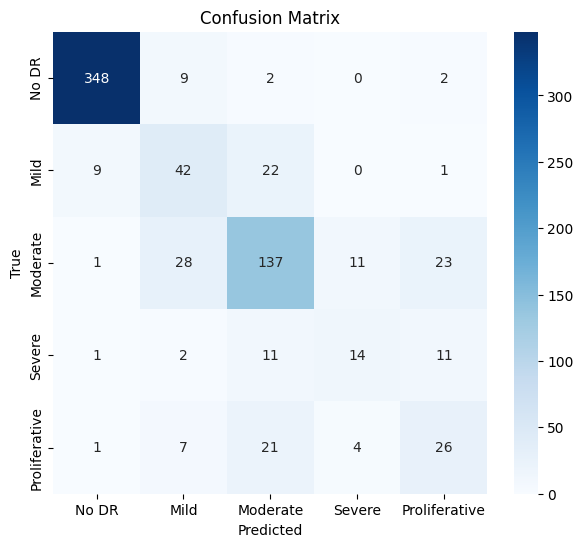

In [ ]:
cm = confusion_matrix(test_targets, test_preds)

class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

plt.figure(figsize=(7,6))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

**ResNet50 Classification Report**

In [ ]:
print(classification_report(test_targets, test_preds))

              precision    recall  f1-score   support

           0       0.97      0.96      0.97       361
           1       0.48      0.57      0.52        74
           2       0.71      0.69      0.70       200
           3       0.48      0.36      0.41        39
           4       0.41      0.44      0.43        59

    accuracy                           0.77       733
   macro avg       0.61      0.60      0.60       733
weighted avg       0.78      0.77      0.77       733



**Train and val loss curves**

In [ ]:
def plot_training_curves(train_losses, val_losses, train_accs, val_accs, train_qwks, val_qwks, model_name):
    epochs = range(1, len(train_losses) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs, train_losses, label='Train Loss', marker='o')
    axes[0].plot(epochs, val_losses, label='Val Loss', marker='o')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{model_name} — Loss Curve')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, train_accs, label='Train Acc', marker='o')
    axes[1].plot(epochs, val_accs, label='Val Acc', marker='o')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{model_name} — Accuracy Curve')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(epochs, train_qwks, label='Train QWK', marker='o')
    axes[2].plot(epochs, val_qwks, label='Val QWK', marker='o')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('QWK')
    axes[2].set_title(f'{model_name} — QWK Curve')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{model_name}_training_curves.png', dpi=150)
    plt.show()

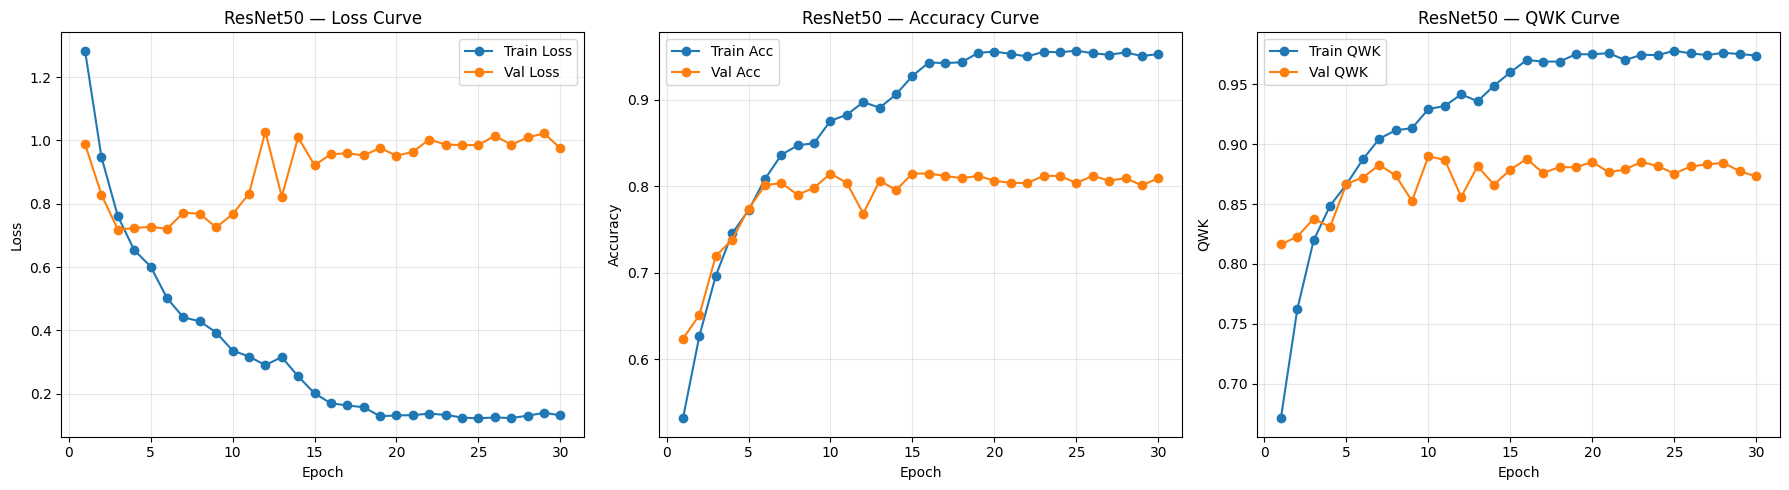

In [ ]:
plot_training_curves(train_losses, val_losses, train_accs, val_accs, train_qwks, val_qwks, "ResNet50")

# **EfficientNet-B0**

**Loading the EfficientNet-B0 image model pre-trained on the ImageNet-1K dataset**

In [ ]:
eff_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

num_features = eff_model.classifier[1].in_features # Determining how many features go into the classifer layer of the EfficientNetB0.

eff_model.classifier = nn.Sequential(
    nn.Dropout(0.5), # Randomly turns off 50% of the neural connections during training. Prevents overfitting.
    nn.Linear(num_features, 5) # Takes 1280 features and maps them to 5 classes to predict the 5 classes of DR.
)

eff_model = eff_model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 182MB/s]


**Skipping if EfficientNetB0 weights already exists**

In [ ]:
drive_model_dir = "/content/drive/MyDrive/aptos2019-blindness-detection/models"
os.makedirs(drive_model_dir, exist_ok=True)
checkpoint_path = os.path.join(drive_model_dir, "efficientnetb0_best_model.pth")

efficientnetb0_skip_training = os.path.exists(checkpoint_path)

if efficientnetb0_skip_training:
    print(f"Found existing weights at {checkpoint_path} -- loading them and skipping training.")
    eff_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    eff_model = eff_model.to(device)
else:
    print("No saved weights found on Drive -- will train from scratch.")

No saved weights found on Drive -- will train from scratch.


**Freeze backbone**

In [ ]:
for param in eff_model.parameters():
    param.requires_grad = False

for param in eff_model.classifier.parameters():
    param.requires_grad = True

**CrossEntropyLoss with class weights to addresses imbalance. The AdamW optimizer updates only the classifier with weight decay for better generalization.**

In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    eff_model.classifier.parameters(),
    lr=4e-3,
    weight_decay=1e-4
)

**Training the head of our model**

In [ ]:
if not efficientnetb0_skip_training:
  EPOCHS = 5

  train_losses = []
  val_losses = []
  train_accs = []
  val_accs = []

  scaler = GradScaler()

  for epoch in range(EPOCHS):

      eff_model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = eff_model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)
      train_acc = accuracy_score(train_targets, train_preds)

      eff_model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              with autocast():
                  outputs = eff_model(images)
                  loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)
      val_acc = accuracy_score(val_targets, val_preds)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      print(f"Epoch {epoch+1}/{EPOCHS}")
      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
      print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
      print("-"*40)
else:
    print("Skipping training -- using loaded weights")

**Unfreeze last 4 blocks + head.**

In [ ]:
for param in eff_model.parameters():
    param.requires_grad = False

for param in eff_model.features[-4:].parameters():
    param.requires_grad = True

for param in eff_model.classifier.parameters():
    param.requires_grad = True

**The model is partially fine-tuned by unfreezing the last 4 blocks of the EfficientNet feature extractor along with the classifier head, while keeping earlier layers frozen.**

In [ ]:
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, eff_model.parameters()),
    lr=5e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.1,
    patience=3,
    min_lr=1e-7
)

**EfficientNetB0 Finetuning Configuration**

In [ ]:
best_qwk = 0

EPOCHS = 30

train_losses = []
val_losses = []

train_accs = []
val_accs = []

train_qwks = []
val_qwks = []

**EfficientNetB0 finetuning**

In [ ]:
if not efficientnetb0_skip_training:
  scaler = GradScaler()

  for epoch in range(EPOCHS):

      eff_model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = eff_model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)

      train_acc = accuracy_score(train_targets, train_preds)
      train_qwk = compute_qwk(train_targets, train_preds)

      eff_model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              with autocast():
                  outputs = eff_model(images)
                  loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)

      val_acc = accuracy_score(val_targets, val_preds)
      val_qwk = compute_qwk(val_targets, val_preds)

      scheduler.step(val_qwk)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      train_qwks.append(train_qwk)
      val_qwks.append(val_qwk)

      if val_qwk > best_qwk:
          best_qwk = val_qwk
          torch.save(eff_model.state_dict(), "efficientnetb0_best_model.pth")

      print(f"Epoch {epoch+1}/{EPOCHS}")

      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train QWK: {train_qwk:.4f}")

      print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f} | Val   QWK: {val_qwk:.4f}")

      print("-"*50)

else:
  print("Skipping training -- using loaded weights")

In [ ]:
if not os.path.exists("/content/drive/MyDrive"):
    raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') first.")

if not efficientnetb0_skip_training and os.path.exists("efficientnetb0_best_model.pth"):
    eff_model.load_state_dict(torch.load("efficientnetb0_best_model.pth", map_location=device))
    eff_model = eff_model.to(device)

DRIVE_MODEL_DIR = "/content/drive/MyDrive/aptos2019-blindness-detection/models"
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(DRIVE_MODEL_DIR, "efficientnetb0_best_model.pth")

torch.save(eff_model.state_dict(), CHECKPOINT_PATH)

# Confirm it actually landed there
if os.path.exists(CHECKPOINT_PATH):
    size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 * 1024)
    print(f"Saved successfully: {CHECKPOINT_PATH} ({size_mb:.1f} MB)")
else:
    print("Save failed -- file not found after torch.save.")

**Saving model history**

In [ ]:
HISTORY_PATH = os.path.join(DRIVE_MODEL_DIR, "efficientnetb0_history.json")

if os.path.exists(HISTORY_PATH):
    print(f"History already exists at {HISTORY_PATH}, loading instead of overwriting.")
    with open(HISTORY_PATH, "r") as f:
        eff_history = json.load(f)
    train_losses = eff_history["train_losses"]
    val_losses = eff_history["val_losses"]
    train_accs = eff_history["train_accs"]
    val_accs = eff_history["val_accs"]
    train_qwks = eff_history["train_qwks"]
    val_qwks = eff_history["val_qwks"]
else:
    eff_history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "train_qwks": train_qwks,
        "val_qwks": val_qwks,
    }
    with open(HISTORY_PATH, "w") as f:
        json.dump(eff_history, f)
    print(f"Saved training history to {HISTORY_PATH}")

**Evaluating the EfficientNetB0 model**

In [ ]:
eff_model.load_state_dict(torch.load("/content/drive/MyDrive/aptos2019-blindness-detection/models/efficientnetb0_best_model.pth"))
eff_model.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = eff_model(images)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_targets, test_preds)
test_qwk = compute_qwk(test_targets, test_preds)
print(f"Final TEST -- Acc: {test_acc:.4f} | QWK: {test_qwk:.4f}")

**Generating EfficientNetB0 confusion matrix**

In [ ]:
cm = confusion_matrix(test_targets, test_preds)

class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

plt.figure(figsize=(7,6))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

**Generating an EfficientNetB0 classification report**

In [ ]:
print(classification_report(test_targets, test_preds))

**Train and val loss curves:**

In [ ]:
plot_training_curves(train_losses, val_losses, train_accs, val_accs, train_qwks, val_qwks, "EfficientNetB0")